# **Quantum Chaos and Scrambling**

Alexander Del Toro Barba, PhD

This notebook computes out-of-time-order correlators (OTOCs) in the mixed-field Ising chain, by exact time evolution and, for the integrable chain, with free fermions; it measures the butterfly velocity of Haar-random brickwork circuits against the exact value 3/5, recovers information from a black-hole model with the Hayden–Preskill protocol (Yoshida–Kitaev decoder in cirq) and computes the Page curve of random states and of a quench.

How does a local perturbation spread through a quantum many-body system, and how can one tell genuine scrambling apart from the spreading of free quasiparticles and from decoherence?

#### **Background**

In classical mechanics, chaos means that two nearby trajectories separate exponentially fast; the rate is the Lyapunov exponent. Quantum mechanics has no trajectories, and unitary time evolution keeps the overlap of two states constant, so this definition does not carry over. Quantum chaos shows up in three other places instead. The first is how operators grow under time evolution, measured by **out-of-time-order correlators** (OTOCs); Larkin and Ovchinnikov introduced them in 1969 for electrons in superconductors, and Kitaev (2015) and Maldacena, Shenker and Stanford (2016) revived them as a measure of chaos. The second is the statistics of the energy levels, which in chaotic systems repel each other like the eigenvalues of random matrices (Bohigas, Giannoni and Schmit 1984). The third is the eigenstates themselves, which look thermal for every local measurement (eigenstate thermalization). **Scrambling** is the dynamical side of this: information that starts in a few qubits spreads into correlations among many of them. It can then no longer be read from any small part of the system, although the global state stays pure and the process could in principle be reversed.

Scrambling explains how an isolated quantum system thermalizes even though its time evolution is unitary. Black holes are believed to be the fastest scramblers in nature, and the question of how information gets out of an evaporating black hole (Page curve, Hayden–Preskill protocol) is one of the cleanest places where quantum information meets gravity. In quantum computers scrambling is both a resource and an obstacle: random circuits that scramble produce the hard-to-sample distributions behind quantum-advantage experiments, the same randomness makes the gradients of variational circuits vanish (barren plateaus), and OTOCs have been measured with NMR, trapped ions and superconducting qubits to test how well a device controls its own dynamics.

The notebook uses exact simulations of small systems (up to 12 qubits) and one exactly solvable model (free fermions, here 24 qubits).

Map:

- **Operator spreading in a spin chain**
  - Light cone in the mixed-field Ising chain (Exp. 1): in both the integrable and the chaotic chain the OTOC front moves ballistically, close to the speed of the fastest quasiparticle. Behind the front the integrable chain relaxes and the front bounces between the ends of the chain; the chaotic chain stays scrambled.
- **Butterfly velocity**
  - Random brickwork circuits (Exp. 2): the measured front speed of 0.595 sites per layer matches the exact $v_B = 3/5$.
- **Information and black holes**
  - Hayden–Preskill recovery (Exp. 3): a maximal scrambler returns the diary from one Hawking qubit with fidelity 1; noise lowers the OTOC just as much but recovers nothing.
  - Page curve (Exp. 4): a quench in the chaotic chain entangles half the chain almost as much as a random state does (5.14 against 5.28 bits); the integrable chain stays near 2.8 bits.

Related notebooks: level repulsion and random-matrix statistics in [Random Matrices](https://github.com/deltorobarba/science/blob/main/maths/randommatrices.ipynb), classical chaos and Lyapunov exponents in [Dynamical Systems and Chaos](https://github.com/deltorobarba/science/blob/main/maths/chaos.ipynb), entropies and the relative entropy in [Quanteninformationstheorie und Abstandsmaße](https://github.com/deltorobarba/science/blob/main/quantum/quantuminformation.ipynb), and an overview of quantum simulation and quantum dynamics in the notes [Quantum Dynamics](https://github.com/deltorobarba/science/blob/main/quantum/quantumdynamics.md).

#### **Theory**

##### *1. Operator growth in the Heisenberg picture*

In the **Heisenberg picture** the states stay fixed and the operators evolve, $W(t) = e^{iHt}\,W\,e^{-iHt}$ (with $\hbar = 1$). Expanding in nested commutators,
$$W(t) = W + it\,[H, W] - \frac{t^2}{2}\,[H, [H, W]] + \dots ,$$
shows how an operator grows: with a local Hamiltonian, each commutator can enlarge the support of the operator by one site. In the basis of **Pauli strings**, the tensor products of $I$, $X$, $Y$ and $Z$ on all qubits, a single-site operator such as $Z_0$ becomes a superposition of longer and longer strings. **Scrambling** means that the weight spreads over exponentially many strings, so that the operator can no longer be detected with local measurements.

Three questions describe this growth:
- **rate:** how fast does it grow in time? (quantum Lyapunov exponent, Section 4)
- **reach:** how fast does its support grow in space? (butterfly velocity, Section 5)
- **depth:** how complex does it become in operator space? (Krylov complexity, Section 6)

OTOCs and operator growth are **dynamical diagnostics**: they need the time evolution $e^{-iHt}$. Spectral statistics and eigenstate thermalization (Section 8) are **static diagnostics** that use only the eigenvalues and eigenvectors of $H$.

##### *2. The mixed-field Ising chain*

The model of Experiments 1, 3 and 4 is a chain of $N$ qubits with open ends,
$$H = J\sum_{i=0}^{N-2} Z_iZ_{i+1} + h_x\sum_{i=0}^{N-1} X_i + h_z\sum_{i=0}^{N-1} Z_i ,$$
with $J = h_x = 1$. Time is measured in units of $1/J$.

**Integrable for $h_z = 0$** (transverse-field Ising chain). The **Jordan–Wigner transformation** maps the spins to **Majorana fermions**
$$\gamma_{2k} = \Big(\prod_{l<k}X_l\Big)Z_k, \qquad \gamma_{2k+1} = \Big(\prod_{l<k}X_l\Big)Y_k, \qquad \lbrace\gamma_a, \gamma_b\rbrace = 2\delta_{ab} .$$
Then $X_k = i\gamma_{2k}\gamma_{2k+1}$ and $Z_kZ_{k+1} = i\gamma_{2k+1}\gamma_{2k+2}$: the Hamiltonian is quadratic in the fermions, $H = \tfrac i4\sum_{ab}A_{ab}\gamma_a\gamma_b$ with a real antisymmetric $2N\times2N$ matrix $A$. A quadratic Hamiltonian describes **free fermions**: each Majorana evolves linearly, $\gamma_a(t) = \sum_b [e^{At}]_{ab}\,\gamma_b$, and the dynamics of $N$ qubits needs a $2N\times2N$ matrix instead of a $2^N\times2^N$ one. The excitations are **quasiparticles** with energy $\varepsilon_k = 2\sqrt{J^2 + h_x^2 - 2Jh_x\cos k}$ and group velocity $v_k = d\varepsilon_k/dk$, at most
$$v_\text{max} = 2\min(J, h_x) ,$$
which is 2 sites per unit time here. They move ballistically, never scatter, and are reflected at the open ends of the chain.

**Chaotic for $h_z \neq 0$** (here $h_z = 0.5$). Under Jordan–Wigner, $Z_k$ becomes a string of fermion operators, so the longitudinal field is not quadratic: the quasiparticles scatter, and the chain behaves like a generic chaotic system. Kim and Huse (2013) used almost the same parameters (field strengths 1.05 and 0.5) as a standard non-integrable chain.

**The OTOC of the free chain.** With the butterfly $V = X_0 = i\gamma_0\gamma_1$ and the probe $W_j = Z_j$, a string of the Majoranas $\gamma_0, \dots, \gamma_{2j}$, the OTOC of Section 3 can be computed exactly. Conjugating with $Z_j$ leaves the Majoranas inside the string unchanged and flips the sign of all others: $Z_j\gamma_aZ_j = s_a\gamma_a$ with $s_a = +1$ for $a \le 2j$ and $s_a = -1$ otherwise. With $V(-t) = i(u\cdot\gamma)(w\cdot\gamma)$, where $u$ and $w$ are the first two rows of $e^{-At}$, and $D = \mathrm{diag}(s)$, Wick's theorem for the trace of four Majoranas leaves a $2\times2$ determinant:
$$F_j(t) = (u\cdot Du)(w\cdot Dw) - (u\cdot Dw)^2 .$$
The cost grows like $N^3$ instead of $8^N$.

##### *3. The out-of-time-order correlator*

Two operators on distant sites commute at $t = 0$. The **squared commutator**
$$\mathcal C(t) = \big\langle [W(t), V]^\dagger\,[W(t), V] \big\rangle$$
measures how far $W(t)$ has grown into the site of $V$. For operators that are unitary and Hermitian, such as Pauli operators, it equals $2\big(1 - \mathrm{Re}\,F(t)\big)$ with the **out-of-time-order correlator**
$$F(t) = \big\langle W(t)^\dagger\, V^\dagger\, W(t)\, V \big\rangle .$$
This notebook averages over all states, $\langle\cdot\rangle = 2^{-N}\,\mathrm{Tr}(\cdot)$ (infinite temperature), and plots half the squared commutator, $C_j(t) = 1 - \mathrm{Re}\,F_j(t)$ for the probe on qubit $j$:
- $C = 0$: $W(t)$ and $V$ still commute, the perturbation has not arrived;
- $C = 1$ ($F = 0$): the value of a fully scrambled operator, which commutes with $V$ in half of its Pauli strings and anticommutes in the other half;
- $C$ up to 2: $W(t)$ anticommutes with $V$, as $Z_0$ and $X_0$ do at $t = 0$.

**Why "out of time order":** In $F(t)$ the time arguments run $t \to 0 \to t \to 0$. Such a correlator cannot be written as an ordinary time-ordered expectation value, whose time contour runs forward only once. Ordinary two-point functions such as $\langle W(t)W\rangle$ decay already on the local thermalization time and are blind to the later spreading of correlations among many qubits; the OTOC keeps track of it.

**Measurement as an echo** (Loschmidt echo): evolve forward with $e^{-iHt}$, apply the butterfly $V$, evolve backward with $e^{+iHt}$ (on hardware by reversing the sign of $H$), and measure the overlap with the probe $W$. Everything that commutes with $V$ cancels between the forward and the backward evolution; only the non-commuting part survives.

##### *4. Rate: the quantum Lyapunov exponent*

In systems with a large number $N$ of degrees of freedom per site, and in semiclassical systems, the squared commutator first grows exponentially, $\mathcal C(t) \sim \frac1N e^{\lambda_Lt}$, with the **quantum Lyapunov exponent** $\lambda_L$. In the semiclassical limit the commutator becomes a Poisson bracket, $-\langle[x(t), p]^2\rangle \to \hbar^2\,\lbrace x(t), p\rbrace^2 \sim \hbar^2e^{2\lambda_\text{cl}t}$, because $\lbrace x(t), p(0)\rbrace = \partial x(t)/\partial x(0)$ measures how much a small change of the initial position grows. This links $\lambda_L$ to the classical Lyapunov exponent.

The time scales are ordered: the **local thermalization time** $t_\text{therm} \sim \mathcal O(1)$, after which local quantities have relaxed; the **scrambling time** $t_\ast \sim \lambda_L^{-1}\ln N$, after which the commutator is of order one everywhere; and the **Heisenberg time** $t_H \sim e^{S}$, the inverse level spacing, after which the discreteness of the spectrum shows (with $S$ the entropy). A **Poincaré recurrence**, a near return to the initial state, takes much longer still.

In spin-1/2 chains with short-range interactions there is no large parameter $N$ per site; the exponential regime is short or absent, and the speed of the front (Section 5) is the quantity that can be measured robustly.

##### *5. Reach: butterfly velocity and the Lieb–Robinson bound*

Far from the butterfly the squared commutator stays small until a front arrives. It moves with the **butterfly velocity** $v_B$; in large-$N$ systems $\mathcal C(t, x) \sim \frac1N\exp[\lambda_L(t - x/v_B)]$.

The **Lieb–Robinson bound** holds for every Hamiltonian with local interactions: $\Vert[A(t), B]\Vert \le c\,e^{-\mu(d - v_\text{LR}t)}$ for operators $A$ and $B$ at distance $d$. Outside the light cone $d > v_\text{LR}t$ every commutator is exponentially small. $v_\text{LR}$ is a property of $H$ alone (a bound on operator norms), whereas $v_B$ depends on the state and the temperature, and $v_B \le v_\text{LR}$. In the free-fermion chain the front moves with the fastest quasiparticle, $v_\text{max}$.

**Random circuits.** In a brickwork circuit of Haar-random two-qudit gates with local dimension $q$, the circuit-averaged OTOC is exactly solvable: the right end of the growing operator performs a biased random walk. This gives
$$v_B = \frac{q^2 - 1}{q^2 + 1} \qquad (= 3/5 \text{ for qubits}),$$
in units where the strict light cone moves one site per layer, and a front whose width grows like $\sqrt t$ (Nahum, Vijay and Haah 2018; von Keyserlingk, Rakovszky, Pollmann and Sondhi 2018).

**Entanglement and circuit depth.** After a quench the entanglement entropy of half the chain grows linearly, $S(t) \approx v_E\,t$, with an **entanglement velocity** $v_E \le v_B$ (Mezei and Stanford 2017). Its fluctuations in one dimension, and the fluctuations of the OTOC front in two dimensions, belong to the Kardar–Parisi–Zhang (KPZ) universality class, with a width growing like $t^{1/3}$. Because information must cross the whole device, entangling all $n$ qubits takes a depth of order $n$ in one dimension, $\sqrt n$ in two dimensions and $\log n$ with all-to-all connections.

##### *6. Depth: Krylov complexity*

Repeated commutators with $H$ span the **Krylov space** $\mathcal K = \mathrm{span}\lbrace W, [H, W], [H, [H, W]], \dots\rbrace$. The Lanczos algorithm builds an orthonormal basis $O_0, O_1, \dots$ of it in which the Liouvillian $\mathcal L = [H, \cdot\,]$ is tridiagonal, with the **Lanczos coefficients** $b_n$ as hopping amplitudes. The operator becomes a wave on a half-infinite chain, $W(t) = \sum_n i^n\varphi_n(t)\,O_n$, and the **Krylov complexity**
$$K(t) = \sum_n n\,\vert\varphi_n(t)\vert^2$$
is its mean position. The growth of $b_n$ sets the growth of $K$: constant $b_n$ give $K \propto t$, $b_n \propto \sqrt n$ give $K \propto t^2$, and linear growth $b_n \approx \alpha n$ gives $K \sim e^{2\alpha t}$. The **universal operator growth hypothesis** (Parker et al. 2019) states that in chaotic systems the $b_n$ grow as fast as possible, linearly (with a logarithmic correction in one dimension). The growth rate bounds the Lyapunov exponent, $\lambda_L \le 2\alpha$.

##### *7. Bounds and the SYK model*

At temperature $T = 1/\beta$ the **Maldacena–Shenker–Stanford (MSS) bound** limits chaos:
$$\lambda_L \le \frac{2\pi k_BT}{\hbar} = \frac{2\pi}{\beta} .$$
It follows from the analyticity of thermal correlators in the strip $0 \le \mathrm{Im}\,t \le \beta$ (the **KMS condition**). Parker et al. argue that the same analyticity limits the Lanczos growth to $\alpha \le \pi/\beta$, which together with $\lambda_L \le 2\alpha$ gives the MSS bound again.

The **Sachdev–Ye–Kitaev (SYK) model** consists of $N$ Majorana fermions with random all-to-all four-body interactions. It is exactly solvable at large $N$, at low temperature it is dual to a two-dimensional theory of gravity (Jackiw–Teitelboim gravity in $\mathrm{AdS}_2$), and it saturates the bound, $\lambda_L = 2\pi/\beta$. Black holes saturate it as well; their scrambling time $t_\ast \sim \frac{\beta}{2\pi}\ln S$ is the shortest possible, and Sekino and Susskind (2008) conjectured that black holes are the fastest scramblers in nature.

##### *8. Static signatures: spectral statistics and eigenstate thermalization*

**Level statistics.** By the Bohigas–Giannoni–Schmit conjecture, the energy levels of a chaotic quantum system have the statistics of a random matrix: neighbouring levels repel each other (**Wigner–Dyson** statistics). Integrable systems have uncorrelated levels (**Poisson** statistics, Berry and Tabor). A convenient test is the ratio of consecutive level spacings $s_n$, $r_n = \min(s_n, s_{n+1})/\max(s_n, s_{n+1})$, with mean $\langle r\rangle \approx 0.53$ for real symmetric random matrices (GOE) and $\approx 0.39$ for Poisson. It needs no rescaling of the spectrum, but the levels of different symmetry sectors must be separated first (the open Ising chain has a reflection symmetry).

**Spectral form factor.** $K(t) = \langle\vert\mathrm{Tr}\,e^{-iHt}\vert^2\rangle$, averaged over an ensemble of Hamiltonians, shows a characteristic **dip–ramp–plateau** shape: a fast decay, a linear ramp caused by level repulsion, and a plateau after the Heisenberg time. The ramp reveals correlations between levels long after the OTOCs have saturated.

**Eigenstate thermalization hypothesis (ETH).** In a chaotic system the matrix elements of a local observable in the energy eigenbasis have the form
$$A_{mn} = \mathcal A(\bar E)\,\delta_{mn} + e^{-S(\bar E)/2}\,f_A(\bar E, \omega)\,R_{mn} ,$$
with a smooth function $\mathcal A$ of the mean energy $\bar E$, the entropy $S$, a smooth function $f_A$ of $\bar E$ and $\omega = E_m - E_n$, and random numbers $R_{mn}$. A single eigenstate then looks thermal for every local observable. Integrable systems have many additional conserved quantities (in the free chain, the occupation of every quasiparticle mode) and relax to a **generalized Gibbs ensemble** (GGE) instead of a thermal state. In **many-body localized** systems, local integrals of motion prevent thermalization altogether.

##### *9. Scrambling versus decoherence*

Both make the OTOC decay, for different reasons:
- **Unitary scrambling:** the information is spread reversibly into many-body entanglement and could in principle be reconstructed from the whole system. The entropy of small subsystems rises while the global state stays pure. $F(t) \to 0$ because the operator grows.
- **Decoherence** (an open system, for example described by a Lindblad equation): the information leaks irreversibly into an environment. The entropy of the whole system grows. $F(t) \to 0$ because the coherences are damped.

A decaying OTOC alone can therefore be faked by noise, which produces a false Lyapunov exponent. Yoshida and Yao (2019) showed that the fidelity of the Hayden–Preskill decoder (Section 10) separates the two: it rises only for genuine scrambling.

##### *10. Black holes: Hayden–Preskill and the Page curve*

**Hayden–Preskill.** An old black hole, past its Page time, is maximally entangled with the Hawking radiation it has already emitted. Alice throws a diary of $k$ qubits into it. Hayden and Preskill (2007) showed that once the black hole has scrambled the diary, Bob, who holds the early radiation, can recover it from only slightly more than $k$ newly emitted Hawking qubits: the black hole acts like an information mirror. **Yoshida–Kitaev decoder:** Bob applies $U^\ast$ to his copy of the early radiation together with one half of a fresh EPR pair $(A', R')$, then projects the Hawking qubit $D$ and its partner $D'$ onto an EPR pair. For unitary $U$:
- the success probability $P_\text{EPR}$ equals the OTOC averaged over all Pauli operators on $A$ and $D$;
- the fidelity of the output with an EPR pair is $F_\text{EPR} = 1/(d_A^2\,P_\text{EPR})$, with $d_A$ the dimension of the diary;
- a perfect scrambler gives $P = 1/d_A^2$ and $F = 1$; no scrambling gives $P = 1$ and $F = 1/d_A^2$.

**Page curve.** Page (1993) computed the average entanglement entropy of a subsystem of dimension $m \le k$ in a Haar-random pure state on $mk$ dimensions:
$$S = \sum_{j=k+1}^{mk}\frac1j - \frac{m-1}{2k} \approx \ln m - \frac{m}{2k} .$$
Read the first $l$ of $N$ qubits as the radiation and the rest as the black hole. The entropy of the radiation then rises by about one bit per emitted qubit until the **Page time** $l = N/2$ and falls afterwards: the **Page curve**. For evaporation to be unitary, information must start to come out after the Page time. At $l = N/2$ the entropy stays $1/(2\ln2) \approx 0.72$ bits below the maximum of $N/2$ bits.

##### *11. Scrambling in quantum computers*

- **Barren plateaus:** deep random circuits approximate unitary **2-designs**, ensembles that reproduce the first two moments of the Haar measure. Averaging over the Haar measure then gives exponentially small gradients, $\mathrm{Var}_\theta[\partial_\theta\langle H\rangle] \sim 2^{-n}$ (McClean et al. 2018), so randomly initialized variational circuits cannot be trained.
- **Random circuit sampling:** the output probabilities $p$ of a scrambling circuit on $n$ qubits follow the **Porter–Thomas distribution** $P(p) \approx \mathcal N e^{-\mathcal Np}$ with $\mathcal N = 2^n$. Boixo et al. (2018) estimated that the distribution approaches Porter–Thomas once information has crossed the device, at a depth of order $\sqrt n$ in two dimensions. The weaker property of **anti-concentration**, which hardness arguments rely on, already sets in at a depth of order $\log n$ (Dalzell, Hunter-Jones and Brandão 2022).

#### **Code**

The tools used by several experiments: the Pauli matrices, `site_op` for an operator on one qubit of the chain, and the mixed-field Ising Hamiltonian of Theory, Section 2 as a dense matrix. `H_X = 1` and `H_Z = 0.5` are the fields used everywhere ($J = 1$). The first cell installs `cirq`, Google's library for quantum circuits, which Experiment 3 uses to build and simulate the Hayden–Preskill circuit.

In [1]:
# Colab: install cirq (Google's library for quantum circuits). Locally nothing is installed automatically,
# because pip can change numpy and other packages of a conda environment; install cirq there yourself,
# preferably with conda (conda-forge).
import importlib.util, subprocess, sys
if "google.colab" in sys.modules:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "cirq"], check=True)
elif importlib.util.find_spec("cirq") is None:
    raise ImportError("Missing cirq; please install it locally yourself, preferably with conda (conda-forge), "
                      "so that numpy stays unchanged")

In [2]:
import cirq                      # https://quantumai.google/cirq
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import eigh, expm
from scipy.signal import find_peaks
from scipy.stats import unitary_group

X = np.array([[0, 1], [1, 0]], dtype=complex)
Z = np.array([[1, 0], [0, -1]], dtype=complex)

def site_op(op, j, n):
    """Single-qubit operator `op` on qubit j of an n-qubit chain (qubit 0 = leftmost tensor factor)."""
    mats = [np.eye(2, dtype=complex)] * n
    mats[j] = op
    out = mats[0]
    for m in mats[1:]:
        out = np.kron(out, m)
    return out

def ising_hamiltonian(n, h_x, h_z, J=1.0):
    """Mixed-field Ising chain H = J Σ Z_i Z_{i+1} + h_x Σ X_i + h_z Σ Z_i with open ends (Theory, Section 2).
    h_z = 0: integrable (free fermions), h_z != 0: chaotic."""
    H = sum(J * site_op(Z, i, n) @ site_op(Z, i + 1, n) for i in range(n - 1))
    return H + sum(h_x * site_op(X, i, n) + h_z * site_op(Z, i, n) for i in range(n))

H_X, H_Z = 1.0, 0.5              # field strengths used in all experiments (J = 1)
print("Tools ready: Pauli matrices, site operators, mixed-field Ising Hamiltonian")

Tools ready: Pauli matrices, site operators, mixed-field Ising Hamiltonian


#### **Experiments**

##### *1. The light cone in the Ising chain*

How does the OTOC between a butterfly $X_0$ at the left end of the chain and a probe $Z_j$ spread along the chain, and what happens behind the front in the integrable and in the chaotic chain? Predict first: which of the two chains spreads faster, and in which one does $C$ fall back towards 0 after the front has passed?

The cell computes $C_j(t) = 1 - F_j(t)$ (Theory, Section 3) for $N = 8$ qubits from the exact time evolution $U(t) = e^{-iHt}$, obtained from the eigendecomposition of the $256\times256$ Hamiltonian, for $t$ from 0 to 30 in steps of 0.1. The butterfly is $V = X_0$, the probes are $W_j = Z_j$ on every qubit. The top row shows the integrable ($h_z = 0$) and the chaotic chain ($h_z = 0.5$) with the line $x = v_\text{max}t$ of the fastest quasiparticle. The bottom left shows the far end $j = 7$ over time. The bottom right shows the integrable chain with 24 qubits, computed with the free-fermion formula of Theory, Section 2, which the cell first checks against the exact calculation for 8 qubits. An exact calculation in the $2^{24}$-dimensional space would be out of reach; the free-fermion one takes less than a second.

**Background & key terms:**
- **Butterfly and probe:** $V = X_0$ is the local perturbation, the "butterfly"; $W_j = Z_j$ is the operator that tests whether the perturbation has arrived at qubit $j$.
- **Exact diagonalization:** $H = S\,\mathrm{diag}(E)\,S^\dagger$ gives $e^{-iHt} = S\,\mathrm{diag}(e^{-iEt})\,S^\dagger$ exactly for every $t$; with dense matrices this works up to about 14 qubits.
- **Light cone and front:** the region in the $(t, j)$ plane where $C$ differs from 0, and its edge.
- **Ballistic spreading:** the front moves at a constant speed, its position grows like $t$ (diffusive spreading would grow like $\sqrt t$).
- **Open ends:** the chain stops at qubits 0 and $N - 1$; a signal that arrives at an end is reflected.

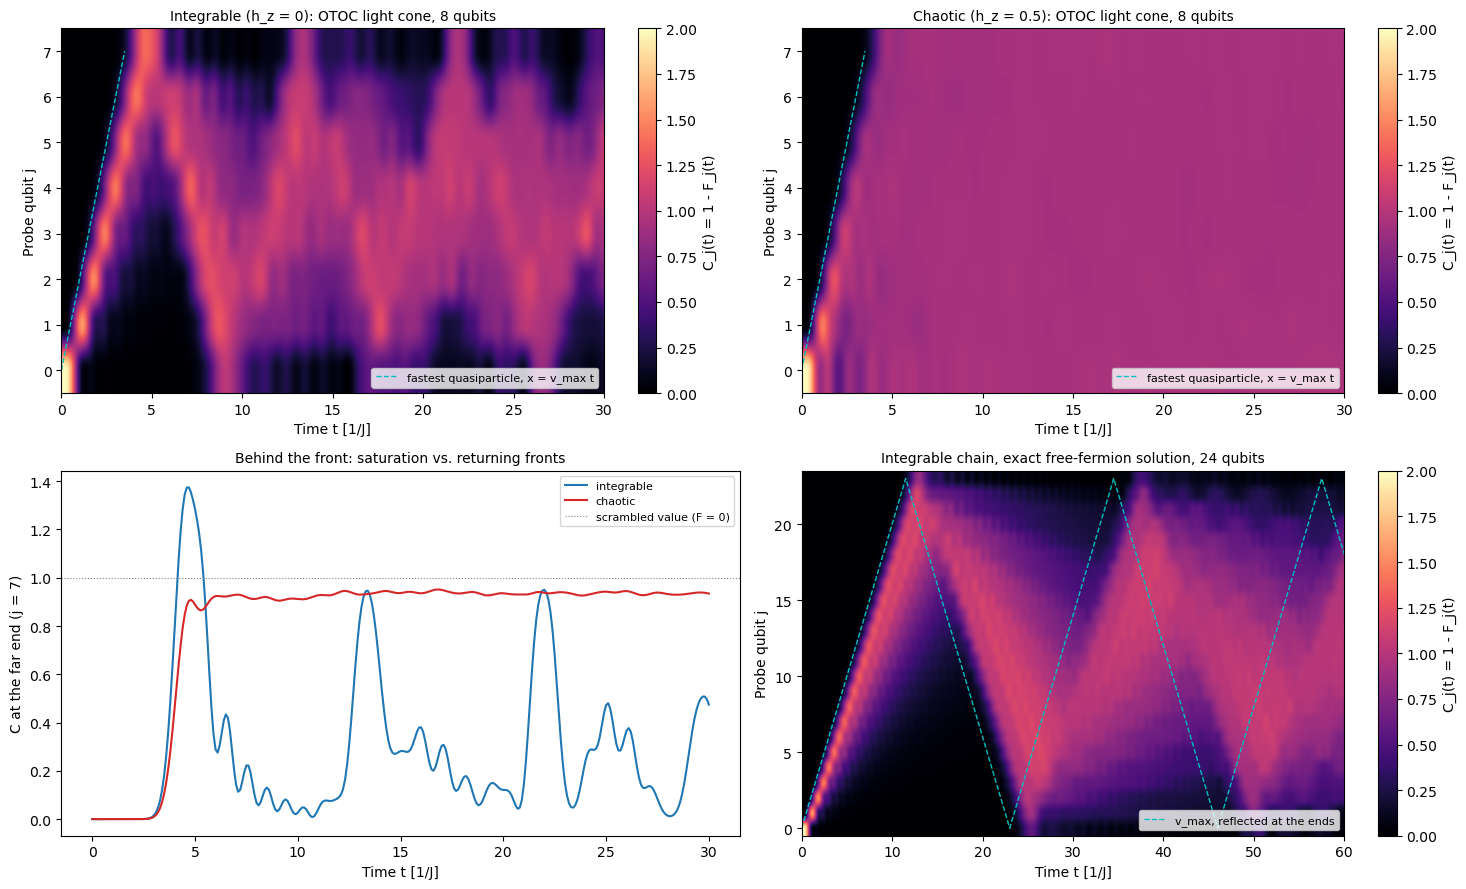

Free fermions vs. exact diagonalization (8 qubits): max deviation 3.0e-13
integrable  front reaches j = 1 ... 7 at t = [0.6 1.2 1.8 2.3 2.8 3.4 3.9]:  speed 1.83 sites per 1/J (v_max = 2)
chaotic     front reaches j = 1 ... 7 at t = [0.6 1.2 1.8 2.4 3.  3.6 4.1]:  speed 1.70 sites per 1/J (v_max = 2)
Late-time average of C (t > 15) at the far end:  integrable 0.27  |  chaotic 0.94
Integrable chain: the front returns to the far end at t = [ 4.7 13.4 22. ]


In [3]:
def otoc_light_cone(n, h_x, h_z, times):
    """C_j(t) = 1 - F_j(t),  F_j(t) = Tr[W_j(t) V W_j(t) V] / 2^n,  butterfly V = X_0, probe W_j = Z_j.
    Exact time evolution U(t) = exp(-iHt) from the eigendecomposition of H."""
    E, S = eigh(ising_hamiltonian(n, h_x, h_z))
    V = site_op(X, 0, n)
    Ws = [site_op(Z, j, n) for j in range(n)]
    C = np.zeros((n, len(times)))
    for k, t in enumerate(times):
        U = (S * np.exp(-1j * E * t)) @ S.conj().T
        for j, W in enumerate(Ws):
            W_t = U.conj().T @ W @ U                                     # Heisenberg picture
            C[j, k] = 1 - np.trace(W_t @ V @ W_t @ V).real / 2 ** n
    return C

def otoc_free_fermions(n, h_x, times, J=1.0):
    """The same OTOC for the integrable chain (h_z = 0) from free Majorana fermions (Theory, Section 2); cost ~ n^3.
    gamma(t) = exp(At) gamma,  X_0 = i gamma_0 gamma_1,  Z_j = string of the Majoranas 0, ..., 2j."""
    A = np.zeros((2 * n, 2 * n))
    A[np.arange(0, 2 * n, 2), np.arange(1, 2 * n, 2)] = 2 * h_x        # h_x X_k     = h_x (i/2)·2 gamma_2k gamma_2k+1
    A[np.arange(1, 2 * n - 2, 2), np.arange(2, 2 * n - 1, 2)] = 2 * J  # J Z_k Z_k+1 = J (i/2)·2 gamma_2k+1 gamma_2k+2
    A = A - A.T
    C = np.zeros((n, len(times)))
    for k, t in enumerate(times):
        u, w = expm(-A * t)[:2]                                        # V(-t) = i (u·gamma)(w·gamma)
        for j in range(n):
            s = np.where(np.arange(2 * n) <= 2 * j, 1.0, -1.0)         # Z_j gamma_a Z_j = s_a gamma_a
            C[j, k] = 1 - ((u @ (s * u)) * (w @ (s * w)) - (u @ (s * w)) ** 2)
    return C

# --- Execution ---
N_QUBITS, T_MAX = 8, 30.0                    # exact diagonalization: 2^8 = 256 states
times = np.linspace(0, T_MAX, 301)
C_int = otoc_light_cone(N_QUBITS, H_X, 0.0, times)
C_chaos = otoc_light_cone(N_QUBITS, H_X, H_Z, times)
C_check = otoc_free_fermions(N_QUBITS, H_X, times)          # must agree with C_int
N_FF, T_FF = 24, 60.0                        # free fermions: a longer chain costs almost nothing
times_ff = np.linspace(0, T_FF, 1201)
C_ff = otoc_free_fermions(N_FF, H_X, times_ff)
V_MAX = 2 * min(1.0, H_X)                    # fastest quasiparticle of the integrable chain, v_max = 2 min(J, h_x)

def bouncing_ray(t, n):
    """Position of a signal that starts at site 0, moves with v_max and is reflected at both open ends."""
    phase = (V_MAX * t) % (2 * (n - 1))
    return np.where(phase <= n - 1, phase, 2 * (n - 1) - phase)

fig, axes = plt.subplots(2, 2, figsize=(15, 9))
t_first = np.linspace(0, (N_QUBITS - 1) / V_MAX, 50)
for ax, C, title in [(axes[0, 0], C_int, "Integrable (h_z = 0)"), (axes[0, 1], C_chaos, f"Chaotic (h_z = {H_Z})")]:
    im = ax.imshow(C, aspect="auto", origin="lower", cmap="magma", vmin=0, vmax=2,
                   extent=[times[0], times[-1], -0.5, N_QUBITS - 0.5])
    ax.plot(t_first, V_MAX * t_first, "c--", lw=1, label="fastest quasiparticle, x = v_max t")
    ax.set_title(f"{title}: OTOC light cone, {N_QUBITS} qubits", fontsize=10)
    ax.set_xlabel("Time t [1/J]")
    ax.set_ylabel("Probe qubit j")
    ax.legend(fontsize=8, loc="lower right")
    fig.colorbar(im, ax=ax, label="C_j(t) = 1 - F_j(t)")
far = N_QUBITS - 1
axes[1, 0].plot(times, C_int[far], label="integrable", c="tab:blue")
axes[1, 0].plot(times, C_chaos[far], label="chaotic", c="tab:red")
axes[1, 0].axhline(1, color="grey", ls=":", lw=0.8, label="scrambled value (F = 0)")
axes[1, 0].set_xlabel("Time t [1/J]")
axes[1, 0].set_ylabel(f"C at the far end (j = {far})")
axes[1, 0].set_title("Behind the front: saturation vs. returning fronts", fontsize=10)
axes[1, 0].legend(fontsize=8)
im = axes[1, 1].imshow(C_ff, aspect="auto", origin="lower", cmap="magma", vmin=0, vmax=2,
                       extent=[times_ff[0], times_ff[-1], -0.5, N_FF - 0.5])
axes[1, 1].plot(times_ff, bouncing_ray(times_ff, N_FF), "c--", lw=1, label="v_max, reflected at the ends")
axes[1, 1].set_xlim(times_ff[0], times_ff[-1])
axes[1, 1].set_title(f"Integrable chain, exact free-fermion solution, {N_FF} qubits", fontsize=10)
axes[1, 1].set_xlabel("Time t [1/J]")
axes[1, 1].set_ylabel("Probe qubit j")
axes[1, 1].legend(fontsize=8, loc="lower right")
fig.colorbar(im, ax=axes[1, 1], label="C_j(t) = 1 - F_j(t)")
plt.tight_layout()
plt.show()

def front_speed(C):
    """Arrival time = first time C_j reaches 1/2; the slope of j against it (j = 1 ... n-1) is the front speed."""
    arrival = np.array([times[np.argmax(C[j] >= 0.5)] for j in range(1, C.shape[0])])
    return np.polyfit(arrival, np.arange(1, C.shape[0]), 1)[0], arrival
late = times > T_MAX / 2
peaks, _ = find_peaks(C_int[far], height=0.7)
print(f"Free fermions vs. exact diagonalization ({N_QUBITS} qubits): max deviation {np.abs(C_check - C_int).max():.1e}")
for label, C in [("integrable", C_int), ("chaotic", C_chaos)]:
    v, arrival = front_speed(C)
    print(f"{label:11s} front reaches j = 1 ... {far} at t = {np.round(arrival, 2)}:  speed {v:.2f} sites per 1/J (v_max = {V_MAX:.0f})")
print(f"Late-time average of C (t > {T_MAX / 2:.0f}) at the far end:  integrable {C_int[far, late].mean():.2f}  |  chaotic {C_chaos[far, late].mean():.2f}")
print(f"Integrable chain: the front returns to the far end at t = {np.round(times[peaks], 1)}")

* The **top row** shows $C_j(t)$ as colour, with the probe qubit $j$ upwards and time to the right. In both chains the bright region starts at the butterfly ($C = 2$ at $j = 0$, $t = 0$, because $X_0$ and $Z_0$ anticommute) and moves up along a straight line: the front is **ballistic in both phases**, and it arrives just behind the dashed line of the fastest quasiparticle, $x = v_\text{max}t$ with $v_\text{max} = 2$. Behind the front the two chains differ. In the integrable chain bright stripes run to the far end, are reflected and come back, with dark regions in between: the zigzag or W pattern. The chaotic chain turns uniform at $C \approx 0.9$ to 1 and stays there.
* The **bottom left** picture shows the far end $j = 7$. In the integrable chain $C$ peaks at 1.37 ($F < 0$) at $t = 4.7$ and falls back towards 0; it returns at $t = 13.4$ and $t = 22.0$, each time the reflected front reaches the end again. The chaotic chain rises to about 0.9 and stays: the operator is scrambled and does not unscramble. The **bottom right** picture shows the integrable chain with 24 qubits: the front crosses the chain, is reflected at the far end, comes back and is reflected again. Its leading edge follows the dashed ray of the fastest quasiparticle, which needs $2(N - 1)/v_\text{max} = 23$ time units for a round trip; the brightest part moves somewhat slower and lags further behind after each reflection. The W pattern is therefore the reflection of free quasiparticles at the open ends, not a Poincaré recurrence, which would take vastly longer.
* The **output** confirms that the free-fermion formula agrees with exact diagonalization to $3\cdot10^{-13}$. The front reaches the far end at $t = 3.9$ (integrable) and $4.1$ (chaotic); from the half-height crossings it moves at 1.83 and 1.70 sites per unit time, both below $v_\text{max} = 2$. After $t = 15$ the far end averages $C = 0.27$ in the integrable and $0.94$ in the chaotic chain.

##### *2. Butterfly velocity in random circuits*

How fast does an operator spread in a circuit of random two-qubit gates, and does the measured speed match the exact $v_B = 3/5$? Predict first: the strict light cone moves one site per layer. Is the OTOC front as fast, faster or slower, and why?

The cell simulates 12 qubits, 20 random circuits and 16 layers. The butterfly is $V = Z_0$, evolved through the circuit, and the probes are $W_j = Z_j$. Instead of the normalized trace over all $2^{12}$ states it uses a single Haar-random state (typicality). The front is the position where the circuit-averaged $C_j(t)$ crosses 1/2, and a linear fit over layers 3 to 16, without the points near the right end, gives $v_B$ (Theory, Section 5).

**Background & key terms:**
- **Haar-random gate:** a unitary drawn from the uniform distribution on the group $U(4)$ (the Haar measure). Such a gate has no structure and conserves nothing.
- **Brickwork circuit:** layers of two-qubit gates on the bonds $(0,1), (2,3), \dots$ alternating with $(1,2), (3,4), \dots$; the strict light cone grows by one site per layer.
- **Typicality:** for a random state $\vert\psi\rangle$, $\langle\psi\vert O\vert\psi\rangle$ equals the normalized trace $2^{-N}\mathrm{Tr}\,O$ up to an error of order $2^{-N/2}$, here about 1.5 %.
- **Circuit average:** the OTOC averaged over many random circuits; this average is what the exact theory describes.

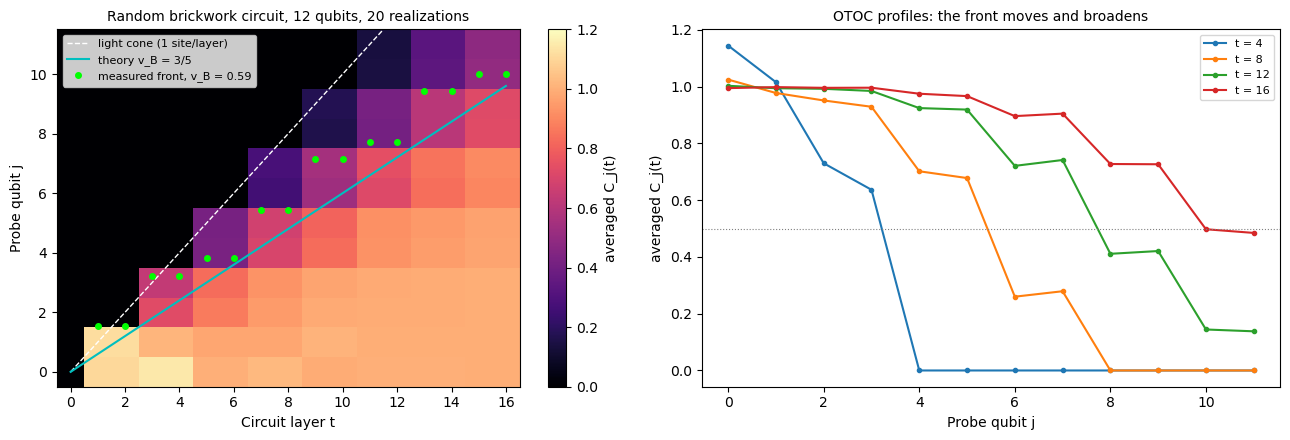

Butterfly velocity (fit over layers 3-16)
  Measured:  v_B = 0.595 sites/layer
  Theory:    v_B = (q² - 1)/(q² + 1) = 0.600   (q = 2, Haar-random gates)
  Light cone:     1 site/layer   ->  information spreads at 60% of the maximal speed


In [4]:
def apply_2q(psi, gate, i, n):
    """Apply a 4x4 gate to qubits (i, i+1) of an n-qubit state vector."""
    psi = psi.reshape([2] * n)
    psi = np.moveaxis(psi, [i, i + 1], [0, 1]).reshape(4, -1)
    psi = (gate @ psi).reshape([2, 2] + [2] * (n - 2))
    return np.moveaxis(psi, [0, 1], [i, i + 1]).reshape(-1)

def apply_1q(psi, op, j, n):
    psi = np.moveaxis(psi.reshape([2] * n), j, 0)
    psi = np.tensordot(op, psi, axes=1)
    return np.moveaxis(psi, 0, j).reshape(-1)

def brickwork(n, depth, rng):
    """Random circuit: layer t applies Haar-random 2-qubit gates on bonds (i, i+1) with i = t mod 2, t mod 2 + 2, ..."""
    return [[(i, unitary_group.rvs(4, random_state=rng)) for i in range(t % 2, n - 1, 2)] for t in range(depth)]

def evolve(psi, layers, n, dagger=False):
    """U|psi> (or U^dagger|psi>) for the circuit U = L_T ... L_1."""
    seq = reversed(layers) if dagger else layers
    for layer in seq:
        for i, g in layer:
            psi = apply_2q(psi, g.conj().T if dagger else g, i, n)
    return psi

def otoc_profile(n, layers, psi):
    """C_j = 1 - Re <psi| V(t) W_j V(t) W_j |psi>,  V = Z_0 (butterfly, evolved), W_j = Z_j (probe).
    A single Haar-random |psi> replaces the normalized trace (typicality, error ~ 2^(-n/2))."""
    C = np.zeros(n)
    for j in range(n):
        phi = apply_1q(psi, Z, j, n)                                   # W_j
        for step in range(2):                                          # (V(t) W_j) twice
            phi = evolve(phi, layers, n)                               # U
            phi = apply_1q(phi, Z, 0, n)                               # V
            phi = evolve(phi, layers, n, dagger=True)                  # U^dagger  -> V(t)
            if step == 0:
                phi = apply_1q(phi, Z, j, n)                           # W_j
        C[j] = 1 - np.vdot(psi, phi).real
    return C

# --- Execution ---
N_RC       = 12     # qubits (state vector 2^12 = 4096)
DEPTH      = 16     # circuit layers; the strict light cone moves 1 site per layer
N_CIRCUITS = 20     # circuit realizations to average over
rng = np.random.default_rng(1)

C_rc = np.zeros((N_CIRCUITS, DEPTH + 1, N_RC))
for r in range(N_CIRCUITS):
    circuit = brickwork(N_RC, DEPTH, rng)
    psi0 = rng.normal(size=2 ** N_RC) + 1j * rng.normal(size=2 ** N_RC)   # Haar-random state
    psi0 /= np.linalg.norm(psi0)
    for t in range(1, DEPTH + 1):
        C_rc[r, t] = otoc_profile(N_RC, circuit[:t], psi0)
C_mean = C_rc.mean(axis=0)                                             # average over circuits

# Front position: where the averaged OTOC crosses half of its scrambled value C = 1
x_front = np.array([np.interp(0.5, C_mean[t][::-1], np.arange(N_RC)[::-1]) if C_mean[t].max() > 0.5 else np.nan
                    for t in range(DEPTH + 1)])
fit = (np.arange(DEPTH + 1) >= 3) & (x_front < N_RC - 2)              # skip start-up and the right boundary
v_fit, x0 = np.polyfit(np.arange(DEPTH + 1)[fit], x_front[fit], 1)
V_THEORY = (2 ** 2 - 1) / (2 ** 2 + 1)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
im = axes[0].imshow(C_mean.T, aspect="auto", origin="lower", cmap="magma", vmin=0, vmax=1.2,
                    extent=[-0.5, DEPTH + 0.5, -0.5, N_RC - 0.5])
tt = np.linspace(0, DEPTH, 100)
axes[0].plot(tt, tt, "w--", lw=1, label="light cone (1 site/layer)")
axes[0].plot(tt, V_THEORY * tt, "c-", lw=1.5, label=f"theory v_B = 3/5")
axes[0].plot(np.arange(DEPTH + 1), x_front, "o", c="lime", ms=4, label=f"measured front, v_B = {v_fit:.2f}")
axes[0].set_ylim(-0.5, N_RC - 0.5)
axes[0].set_xlabel("Circuit layer t")
axes[0].set_ylabel("Probe qubit j")
axes[0].set_title(f"Random brickwork circuit, {N_RC} qubits, {N_CIRCUITS} realizations", fontsize=10)
axes[0].legend(fontsize=8, loc="upper left")
fig.colorbar(im, ax=axes[0], label="averaged C_j(t)")
for t in [4, 8, 12, 16]:
    if t <= DEPTH:
        axes[1].plot(np.arange(N_RC), C_mean[t], "o-", ms=3, label=f"t = {t}")
axes[1].axhline(0.5, color="grey", ls=":", lw=0.8)
axes[1].set_xlabel("Probe qubit j")
axes[1].set_ylabel("averaged C_j(t)")
axes[1].set_title("OTOC profiles: the front moves and broadens", fontsize=10)
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

print(f"Butterfly velocity (fit over layers {np.arange(DEPTH + 1)[fit].min()}-{np.arange(DEPTH + 1)[fit].max()})")
print(f"  Measured:  v_B = {v_fit:.3f} sites/layer")
print(f"  Theory:    v_B = (q² - 1)/(q² + 1) = {V_THEORY:.3f}   (q = 2, Haar-random gates)")
print(f"  Light cone:     1 site/layer   ->  information spreads at {V_THEORY:.0%} of the maximal speed")

* The **left picture** shows the averaged $C_j(t)$ against the layer $t$ (horizontal) and the probe qubit $j$. The white dashed line is the strict light cone (1 site per layer), the cyan line the theory $v_B = 3/5$, and the green points the measured front, which follows the cyan line in steps of two sites, because each gate covers two qubits. Behind the front $C$ approaches the scrambled value 1, as in the chaotic chain of Experiment 1.
* The **right picture** shows the profiles after 4, 8, 12 and 16 layers: close to 1 behind the front, falling to 0 ahead of it. The front moves to the right and gets wider with time (the $\sqrt t$ broadening of the biased random walk). Values slightly above 1 near the butterfly at $t = 4$ come from Pauli strings with an $X$ or $Y$ on qubit 0, which anticommute with $Z_0$ and still carry more than half of the weight there.
* The **output** gives $v_B = 0.595$ sites per layer against the exact $0.600$: information spreads at 60 % of the maximal speed the circuit allows. With 14 qubits, 20 circuits and 20 layers the fit gives 0.594 (about 1.5 minutes, Variation 4).

##### *3. Black holes: recovering information with the Hayden–Preskill protocol*

Can Bob recover Alice's diary from a single Hawking qubit, and can his decoder tell scrambling apart from decoherence? Predict first: what fidelity does Bob get if the black hole does not scramble at all, and what if it only decoheres?

The cell simulates the Yoshida–Kitaev decoder of Theory, Section 10 with 8 qubits in cirq. The diary is one qubit ($d_A = 2$), the black hole has two more qubits, and an explicit reference qubit $R$ makes the fidelity $F_\text{EPR}$ directly computable:

| Qubit | R | A | B1 B2 | B1′ B2′ | A′ | R′ |
|---|---|---|---|---|---|---|
| Role | reference | diary | black hole (B2 = Hawking qubit D) | early radiation (Bob) | decoder EPR half | output |

Four scramblers $U$ on the three black-hole qubits are compared: the time evolution of the 3-qubit Ising chain (chaotic and integrable) for $t$ from 0 to 6, 40 Haar-random unitaries, and a Clifford circuit that scrambles maximally (found by a numerical search). A fifth case has no scrambling at all ($U = 1$) but depolarizing noise inside the black hole.

**Background & key terms:**
- **EPR pair:** the Bell state $(\vert00\rangle + \vert11\rangle)/\sqrt2$ of two maximally entangled qubits.
- **Bell measurement:** a measurement that asks whether two qubits are in this EPR state; here it is computed as a projection on the density matrix, and the success probability is $P_\text{EPR}$.
- **Teleportation fidelity $F_\text{EPR}$:** the overlap of the final state of $(R, R')$ with an EPR pair. $F = 1$ means that the diary has arrived perfectly at $R'$; $F = 1/4$ is what a random guess achieves.
- **Clifford circuit:** a circuit of H, CNOT and CZ gates; it maps every Pauli string to another Pauli string and is efficient to simulate classically.
- **Depolarizing noise:** with probability $p$ the qubit suffers an $X$, $Y$ or $Z$ error (each with $p/3$).
- **Density-matrix simulator:** simulates mixed states $\rho$ instead of state vectors, which noise requires.

Hayden-Preskill circuit with the maximal scrambler:
          ┌──┐
0: ───H────@─────────────
           │
1: ────────X─────U[1]────
                 │
2: ───H────@─────U[2]────
           │     │
3: ───H────┼@────U[3]────
           ││
4: ────────X┼────U*[2]───
            │    │
5: ─────────X────U*[3]───
                 │
6: ───H────@─────U*[1]───
           │
7: ────────X─────────────
          └──┘


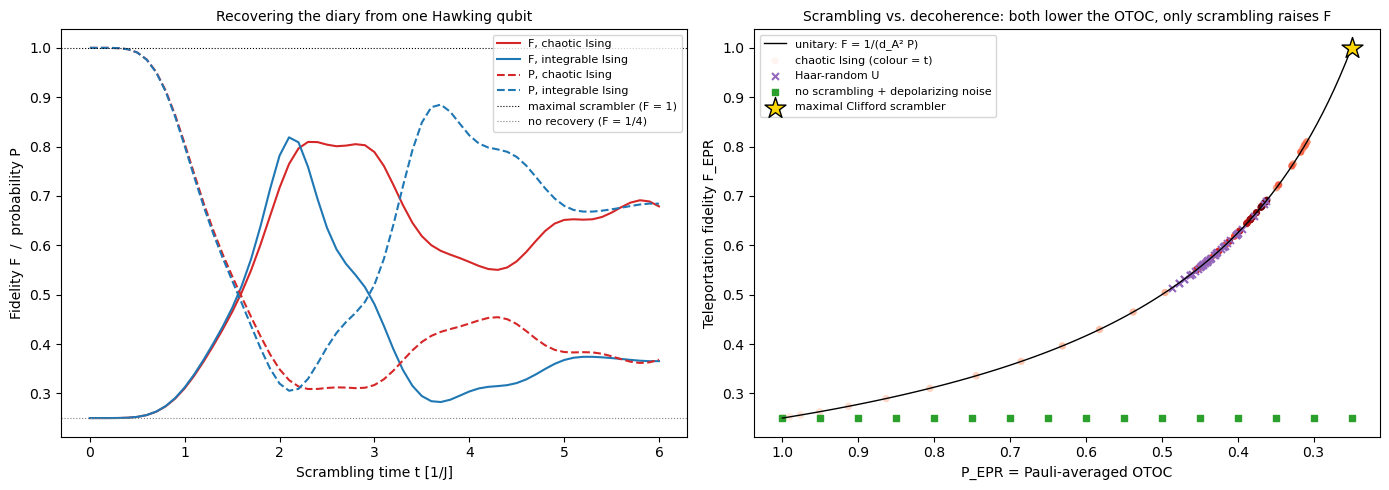

Yoshida-Kitaev decoder (d_A = 2)
  Maximal scrambler:        P = 0.250, F = 1.000   (theory: P = 1/d_A² = 0.25, F = 1)
  Haar-random U (40 draws): F = 0.580 ± 0.041
  Chaotic Ising:            best F = 0.809 at t = 2.3
  Integrable Ising:         best F = 0.819 at t = 2.1, lowest after that F = 0.282
  Depolarizing noise p=0.75: P = 0.250 (OTOC decays), F = 0.250 (no recovery)
  Check F·d_A²·P = 1 for all unitaries: max deviation 3.3e-15


In [5]:
# Qubits: R (reference) - A (Alice's diary) - B1 B2 (black hole) | B1' B2' (early radiation, held by Bob) - A' R' (Bob's decoder pair)
R, A, B1, B2, B1p, B2p, Ap, Rp = cirq.LineQubit.range(8)
QUBITS = [R, A, B1, B2, B1p, B2p, Ap, Rp]

def bell_pair(a, b):
    return [cirq.H(a), cirq.CNOT(a, b)]

def bell_projector(a, b):
    """|Φ+><Φ+| on qubits (a, b) = (II + XX - YY + ZZ)/4, as a 256x256 matrix on all 8 qubits."""
    ps = (cirq.PauliString() + cirq.X(a) * cirq.X(b) - cirq.Y(a) * cirq.Y(b) + cirq.Z(a) * cirq.Z(b)) / 4
    return ps.matrix(QUBITS)

def hayden_preskill_circuit(U, noise=0.0):
    """Diary A (entangled with reference R) falls into black hole B, which is entangled with the early radiation B'.
    U scrambles (A, B1, B2); Bob applies U* to (A', B1', B2'). The Hawking qubit D = B2 is emitted."""
    c = cirq.Circuit(bell_pair(R, A), bell_pair(B1, B1p), bell_pair(B2, B2p), bell_pair(Ap, Rp))
    c.append(cirq.MatrixGate(U, name="U").on(A, B1, B2))
    if noise > 0:                                                     # decoherence inside the black hole
        c.append(cirq.depolarize(noise).on_each(A, B1, B2))
    c.append(cirq.MatrixGate(U.conj(), name="U*").on(Ap, B1p, B2p))
    return c

PROJ_D = bell_projector(B2, B2p)     # Bob's Bell measurement on the Hawking qubit D and its partner D'
PROJ_R = bell_projector(R, Rp)       # success check: is R' now entangled with R?
dm_sim = cirq.DensityMatrixSimulator(dtype=np.complex128)

def decode(U, noise=0.0):
    """Returns (P_EPR, F_EPR): probability of the Bell outcome on (D, D') and fidelity of (R, R') with |Φ+>."""
    rho = dm_sim.simulate(hayden_preskill_circuit(U, noise), qubit_order=QUBITS).final_density_matrix
    P = np.trace(PROJ_D @ rho).real
    F = np.trace(PROJ_R @ PROJ_D @ rho @ PROJ_D).real / P
    return P, F

# Scramblers: time evolution of the 3-qubit Ising chain, Haar-random unitaries, and a maximal Clifford scrambler
q3 = cirq.LineQubit.range(3)
U_MAX = cirq.Circuit(cirq.CZ(q3[0], q3[2]), cirq.CZ(q3[1], q3[2]), cirq.H.on_each(*q3),
                     cirq.CZ(q3[1], q3[2]), cirq.CZ(q3[0], q3[2])).unitary(qubit_order=q3)
bh_times = np.linspace(0, 6, 61)
res_chaos = np.array([decode(expm(-1j * ising_hamiltonian(3, H_X, H_Z) * t)) for t in bh_times])
res_int   = np.array([decode(expm(-1j * ising_hamiltonian(3, H_X, 0.0) * t)) for t in bh_times])
res_haar  = np.array([decode(unitary_group.rvs(8, random_state=s)) for s in range(40)])
res_noise = np.array([decode(np.eye(8), p) for p in np.linspace(0, 0.75, 16)])
P_max, F_max = decode(U_MAX)

print("Hayden-Preskill circuit with the maximal scrambler:")
print(hayden_preskill_circuit(U_MAX))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(bh_times, res_chaos[:, 1], c="tab:red", label="F, chaotic Ising")
axes[0].plot(bh_times, res_int[:, 1], c="tab:blue", label="F, integrable Ising")
axes[0].plot(bh_times, res_chaos[:, 0], c="tab:red", ls="--", label="P, chaotic Ising")
axes[0].plot(bh_times, res_int[:, 0], c="tab:blue", ls="--", label="P, integrable Ising")
axes[0].axhline(1, color="black", lw=0.8, ls=":", label="maximal scrambler (F = 1)")
axes[0].axhline(0.25, color="grey", lw=0.8, ls=":", label="no recovery (F = 1/4)")
axes[0].set_xlabel("Scrambling time t [1/J]")
axes[0].set_ylabel("Fidelity F  /  probability P")
axes[0].set_title("Recovering the diary from one Hawking qubit", fontsize=10)
axes[0].legend(fontsize=8)

PP = np.linspace(0.25, 1, 100)
axes[1].plot(PP, 1 / (4 * PP), c="black", lw=1, label="unitary: F = 1/(d_A² P)")
axes[1].scatter(res_chaos[:, 0], res_chaos[:, 1], c=bh_times, cmap="Reds", s=18, label="chaotic Ising (colour = t)")
axes[1].scatter(res_haar[:, 0], res_haar[:, 1], c="tab:purple", marker="x", s=25, label="Haar-random U")
axes[1].scatter(res_noise[:, 0], res_noise[:, 1], c="tab:green", marker="s", s=20, label="no scrambling + depolarizing noise")
axes[1].scatter([P_max], [F_max], c="gold", edgecolor="black", marker="*", s=250, zorder=5, label="maximal Clifford scrambler")
axes[1].set_xlabel("P_EPR = Pauli-averaged OTOC")
axes[1].set_ylabel("Teleportation fidelity F_EPR")
axes[1].set_title("Scrambling vs. decoherence: both lower the OTOC, only scrambling raises F", fontsize=10)
axes[1].invert_xaxis()
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

i_best = np.argmax(res_chaos[:, 1])
print(f"Yoshida-Kitaev decoder (d_A = 2)")
print(f"  Maximal scrambler:        P = {P_max:.3f}, F = {F_max:.3f}   (theory: P = 1/d_A² = 0.25, F = 1)")
print(f"  Haar-random U (40 draws): F = {res_haar[:, 1].mean():.3f} ± {res_haar[:, 1].std():.3f}")
print(f"  Chaotic Ising:            best F = {res_chaos[i_best, 1]:.3f} at t = {bh_times[i_best]:.1f}")
print(f"  Integrable Ising:         best F = {res_int[:, 1].max():.3f} at t = {bh_times[np.argmax(res_int[:, 1])]:.1f}, "
      f"lowest after that F = {res_int[np.argmax(res_int[:, 1]):, 1].min():.3f}")
print(f"  Depolarizing noise p=0.75: P = {res_noise[-1, 0]:.3f} (OTOC decays), F = {res_noise[-1, 1]:.3f} (no recovery)")
print(f"  Check F·d_A²·P = 1 for all unitaries: max deviation {np.abs(4 * np.r_[res_chaos, res_int, res_haar].prod(axis=1) - 1).max():.1e}")

* The printed **circuit** shows the four EPR pairs (H and CNOT), the scrambler $U$ on $(A, B1, B2)$ and its complex conjugate $U^\ast$ on Bob's side. The **left picture** shows the fidelity $F$ (solid) and the probability $P$ (dashed) against the scrambling time of the 3-qubit Ising chain. At $t = 0$ nothing is scrambled: $P = 1$, $F = 1/4$. As the chain scrambles, $P$ falls and $F$ rises. The chaotic chain reaches $F = 0.81$ at $t = 2.3$ and stays between about 0.55 and 0.8; the integrable chain reaches $0.82$ at $t = 2.1$ but then unscrambles, $P$ climbs back to 0.88 and $F$ drops to $0.28$.
* The **right picture** plots $F$ against $P$. All unitary scramblers lie on the curve $F = 1/(d_A^2P)$: the chaotic chain (red, colour = time), the Haar-random unitaries (purple crosses) around $P \approx 0.43$, and the maximal Clifford scrambler (star) at $P = 1/4$, $F = 1$. The green squares have no scrambling, only depolarizing noise: $P$ falls from 1 to 1/4 just like for a perfect scrambler, but $F$ stays at 1/4. A decaying OTOC alone cannot tell the two apart; the fidelity can.
* The **output** gives $P = 0.250$, $F = 1.000$ for the maximal scrambler and $F = 0.58 \pm 0.04$ for Haar-random unitaries: at this size a typical random unitary is not a perfect scrambler. $F\cdot d_A^2\cdot P = 1$ holds for all unitaries to $3\cdot10^{-15}$. With a Clifford scrambler the circuit contains only H, CNOT and CZ gates and could run on real hardware, where a Bell-basis measurement on $(D, D')$ with post-selection replaces the projection used here; Landsman et al. (2019) did this with 7 trapped-ion qubits.

##### *4. The Page curve: entanglement between black hole and radiation*

Does the entanglement between "radiation" and "black hole" follow the Page curve, and does a quench in the Ising chain produce as much entanglement as a random state? Predict first: how many bits of entanglement does one half of a random 12-qubit state carry, exactly 6 or less?

**Left:** the first $l$ qubits of $N = 12$ play the radiation, the rest the black hole; the cell compares the Page formula (Theory, Section 10), five Haar-random states and the states of the Ising chain at $t = 12$. **Right:** the entropy of half the chain over time after a quench from the product state $\vert{+i}\rangle^{\otimes N}$, the state with every spin along $+y$. This state has $\langle H\rangle = 0$, the energy of infinite temperature, so a chaotic chain should approach the Page value. The time evolution uses sparse matrices (`expm_multiply`), because a dense $4096\times4096$ exponential would be slow.

**Background & key terms:**
- **Entanglement entropy:** the von Neumann entropy $S = -\mathrm{Tr}\,\rho_A\log_2\rho_A$ of the reduced state of a part $A$ of a pure state; it is computed from the singular values of the state vector written as a $2^l\times2^{N-l}$ matrix (Schmidt decomposition).
- **Quench:** a sudden start of the time evolution from a simple initial state, here a product state without entanglement.
- **Infinite temperature:** the thermal state at $\beta = 0$ is the maximally mixed state with energy $\mathrm{Tr}\,H/2^N = 0$; a pure state with the same energy thermalizes towards it locally.
- **Generalized Gibbs ensemble:** the state an integrable system relaxes to, fixed by all its conserved quantities (Theory, Section 8).

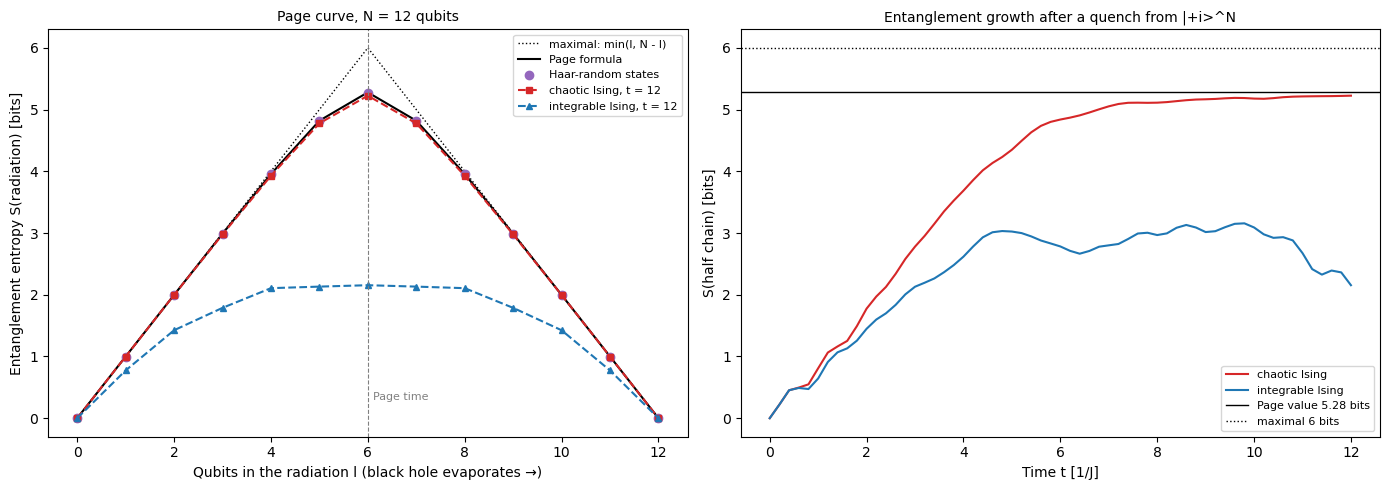

Page curve (N = 12)
  Page value at l = N/2:   5.279 bits  (≈ N/2 - 1/(2 ln 2) = 5.279)
  Haar-random states:      5.274 bits
  Chaotic Ising, late t:   5.135 bits  (time average t > 6)
  Integrable Ising, late t: 2.841 bits


In [6]:
from scipy import sparse
from scipy.sparse.linalg import expm_multiply

def ising_hamiltonian_sparse(n, h_x, h_z, J=1.0):
    """Same Hamiltonian as ising_hamiltonian, as a sparse matrix (needed for n > 10)."""
    def op(o, j):
        return sparse.kron(sparse.kron(sparse.identity(2 ** j), sparse.csr_matrix(o)), sparse.identity(2 ** (n - j - 1)), format="csr")
    H = sum(J * op(Z, i) @ op(Z, i + 1) for i in range(n - 1))
    return H + sum(h_x * op(X, i) + h_z * op(Z, i) for i in range(n))

def entanglement_entropy(psi, l, n):
    """Von Neumann entropy (in bits) of the first l qubits of an n-qubit pure state."""
    if l in (0, n):
        return 0.0
    s = np.linalg.svd(psi.reshape(2 ** l, 2 ** (n - l)), compute_uv=False)
    p = s[s > 1e-12] ** 2
    return float(-(p * np.log2(p)).sum())

def page_entropy(l, n):
    """Page (1993): average entropy of a subsystem of dimension m <= k in a Haar-random state on m*k (in bits)."""
    m, k = sorted([2 ** l, 2 ** (n - l)])
    return (sum(1 / j for j in range(k + 1, m * k + 1)) - (m - 1) / (2 * k)) / np.log(2)

# --- Execution ---
N_PAGE = 12
ells = np.arange(N_PAGE + 1)
rng = np.random.default_rng(7)

# (a) Page curve: Haar-random states vs. Page's formula vs. the naive bound min(l, n - l)
haar_states = [(lambda v: v / np.linalg.norm(v))(rng.normal(size=2 ** N_PAGE) + 1j * rng.normal(size=2 ** N_PAGE)) for _ in range(5)]
S_haar = np.array([[entanglement_entropy(psi, l, N_PAGE) for l in ells] for psi in haar_states]).mean(axis=0)
S_page = np.array([page_entropy(l, N_PAGE) for l in ells])

# (b) Dynamics: half-chain entropy after a quench from the product state |+i>^N under the Ising chain
#     (<H> = 0 for this state, i.e. infinite temperature; |00...0> sits at the edge of the spectrum and entangles little)
page_times = np.linspace(0, 12, 61)
plus_i = np.array([1, 1j]) / np.sqrt(2)
psi_init = plus_i
for _ in range(N_PAGE - 1):
    psi_init = np.kron(psi_init, plus_i)
S_t = {}
for label, hz in [("chaotic", H_Z), ("integrable", 0.0)]:
    H_sp = ising_hamiltonian_sparse(N_PAGE, H_X, hz)
    states = expm_multiply(-1j * H_sp, psi_init, start=page_times[0], stop=page_times[-1], num=len(page_times), endpoint=True)
    S_t[label] = np.array([entanglement_entropy(psi, N_PAGE // 2, N_PAGE) for psi in states])
    S_t[label + "_curve"] = np.array([entanglement_entropy(states[-1], l, N_PAGE) for l in ells])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(ells, np.minimum(ells, N_PAGE - ells), "k:", lw=1, label="maximal: min(l, N - l)")
axes[0].plot(ells, S_page, "k-", lw=1.5, label="Page formula")
axes[0].plot(ells, S_haar, "o", c="tab:purple", label="Haar-random states")
axes[0].plot(ells, S_t["chaotic_curve"], "s--", c="tab:red", ms=5, label=f"chaotic Ising, t = {page_times[-1]:.0f}")
axes[0].plot(ells, S_t["integrable_curve"], "^--", c="tab:blue", ms=5, label=f"integrable Ising, t = {page_times[-1]:.0f}")
axes[0].axvline(N_PAGE / 2, color="grey", lw=0.8, ls="--")
axes[0].text(N_PAGE / 2 + 0.1, 0.3, "Page time", color="grey", fontsize=8)
axes[0].set_xlabel("Qubits in the radiation l (black hole evaporates →)")
axes[0].set_ylabel("Entanglement entropy S(radiation) [bits]")
axes[0].set_title(f"Page curve, N = {N_PAGE} qubits", fontsize=10)
axes[0].legend(fontsize=8)

axes[1].plot(page_times, S_t["chaotic"], c="tab:red", label="chaotic Ising")
axes[1].plot(page_times, S_t["integrable"], c="tab:blue", label="integrable Ising")
axes[1].axhline(page_entropy(N_PAGE // 2, N_PAGE), color="black", ls="-", lw=1, label=f"Page value {page_entropy(N_PAGE // 2, N_PAGE):.2f} bits")
axes[1].axhline(N_PAGE / 2, color="black", ls=":", lw=1, label=f"maximal {N_PAGE // 2} bits")
axes[1].set_xlabel("Time t [1/J]")
axes[1].set_ylabel(f"S(half chain) [bits]")
axes[1].set_title("Entanglement growth after a quench from |+i>^N", fontsize=10)
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

late = page_times > page_times[-1] / 2
print(f"Page curve (N = {N_PAGE})")
print(f"  Page value at l = N/2:   {S_page[N_PAGE // 2]:.3f} bits  (≈ N/2 - 1/(2 ln 2) = {N_PAGE / 2 - 1 / (2 * np.log(2)):.3f})")
print(f"  Haar-random states:      {S_haar[N_PAGE // 2]:.3f} bits")
print(f"  Chaotic Ising, late t:   {S_t['chaotic'][late].mean():.3f} bits  (time average t > {page_times[-1] / 2:.0f})")
print(f"  Integrable Ising, late t: {S_t['integrable'][late].mean():.3f} bits")

* The **left picture** shows the entropy of the first $l$ qubits against $l$. The dotted line is the maximum $\min(l, N - l)$, the black line the Page formula, which bends below the maximum near the middle. The Haar-random states (purple) lie on the Page curve, and so does the chaotic chain at $t = 12$ (red): its state looks like a random state. The integrable chain (blue) stays far below, at about 2.1 bits in the middle.
* The **right picture** shows the entropy of half the chain against time. Both chains start with a linear rise, the growth $S \approx v_Et$ of Theory, Section 5. The chaotic chain keeps rising until $t \approx 7$ and then settles just below the Page value; the integrable chain stops at about 3 bits and fluctuates between 2.2 and 3.2 bits.
* The **output** gives the Page value $5.279$ bits $= 6 - 1/(2\ln2)$, and $5.274$ bits for the Haar-random states. The chaotic chain reaches $5.135$ bits on average after $t = 6$, close to the Page value. The integrable chain averages $2.841$ bits: the free-fermion chain does not thermalize to a random state but relaxes to a generalized Gibbs ensemble with lower entropy.

#### **Results**

From the run on 2026-10-24:

- **Light cone (Experiment 1):** in the mixed-field Ising chain with 8 qubits the OTOC front is ballistic in both phases and reaches the far end at $t = 3.9$ (integrable) and $4.1$ (chaotic), moving at 1.83 and 1.70 sites per unit time, just below the fastest quasiparticle, $v_\text{max} = 2$. The difference lies behind the front: the integrable chain relaxes towards $C = 0$ (late average at the far end 0.27), and its front is reflected at the open ends and returns at $t = 13.4$ and $22.0$; the chaotic chain saturates near the scrambled value (0.94). The free-fermion solution reproduces the exact integrable result to $3\cdot10^{-13}$ and shows the same zigzag for 24 qubits.
- **Butterfly velocity (Experiment 2):** $v_B = 0.595$ sites per layer in random brickwork circuits (12 qubits, 20 circuits), against the exact $(q^2-1)/(q^2+1) = 0.600$; with 14 qubits and 20 layers 0.594.
- **Hayden–Preskill (Experiment 3):** the maximal Clifford scrambler gives $P = 0.250$, $F = 1.000$; Haar-random 3-qubit unitaries $F = 0.58 \pm 0.04$; the chaotic Ising chain up to $F = 0.81$ and stays scrambled, the integrable one reaches $0.82$ and unscrambles again (down to $0.28$). Depolarizing noise lowers $P$ to 0.25 like a scrambler, but $F$ stays at 1/4. $F\,d_A^2P = 1$ holds for all unitaries to $3\cdot10^{-15}$.
- **Page curve (Experiment 4):** Page value at $l = N/2$ 5.279 bits, Haar-random states 5.274 bits. After a quench from $\vert{+i}\rangle^{\otimes 12}$ the chaotic chain reaches 5.14 bits, close to the Page value, and its late-time Page curve lies on the random-state curve; the integrable chain stays near 2.8 bits (generalized Gibbs ensemble).

#### **Variations**

Write down the prediction first, then change the code:

1. **Butterfly in the middle:** in Experiment 1, use $V = X_{N/2}$ (`site_op(X, n // 2, n)`). For the free-fermion version, take the rows $N$ and $N+1$ of $e^{-At}$ instead of the first two. *(Prediction: two fronts run to both ends in half the time; in the integrable chain they are reflected and cross in the middle.)*
2. **Weak chaos:** set `H_Z = 0.1`. *(Prediction: the front stays ballistic, and the returning fronts are still visible at the far end; but between them $C$ no longer falls back to 0 and drifts towards the scrambled value, with a late average of about 0.8 instead of 0.27.)*
3. **Away from the critical point:** set `H_X = 0.5`. *(Prediction: $v_\text{max} = 2\min(J, h_x) = 1$, so the front needs about twice as long and reaches $j = 6$ only at $t \approx 7$. The last qubit hardly reacts at all: for $h_x < J$ the chain is in its ordered phase, where $Z$ on the end qubit is almost conserved, a Majorana edge mode.)*
4. **Larger random circuits:** in Experiment 2, set `N_RC = 14` and `DEPTH = 20` (about 1.5 minutes). *(Prediction: $v_B$ stays near 0.6; the run on 2026-10-24 gave 0.594.)*
5. **Scrambling plus noise:** in Experiment 3, call `decode(U_MAX, p)` for $p = 0.05$ and $0.2$. *(Prediction: $P$ stays at 1/4, but $F$ falls to about 0.95 and 0.80; $F\,d_A^2P$ is no longer 1, because the evolution is not unitary.)*
6. **Quench from the edge of the spectrum:** in Experiment 4, start from $\vert 0\dots0\rangle$ instead of $\vert{+i}\rangle^{\otimes N}$. *(Prediction: this state has the energy $\langle H\rangle = (N-1)J + Nh_z = 17$, close to the top of the spectrum at 19.7 and far from infinite temperature, so even the chaotic chain stays near 1 bit instead of 5.28.)*

#### **Review**

Answer first, then unfold.

<details><summary>1. Why does the classical definition of chaos not carry over to quantum mechanics, and what replaces it?</summary>

Classical chaos is the exponential separation of nearby trajectories. Quantum mechanics has no trajectories, and unitary evolution keeps the overlap of two states constant. Instead one looks at how operators grow (OTOCs), at the statistics of energy levels (random-matrix level repulsion) and at the eigenstates (ETH).
</details>

<details><summary>2. What does the OTOC measure, and what do the values C = 0, C = 1 and C = 2 mean?</summary>

It measures how much $W(t)$ fails to commute with $V$: $C = 1 - \mathrm{Re}\,F$ is half the squared commutator. $C = 0$: they still commute, the perturbation has not arrived. $C = 1$ ($F = 0$): $W(t)$ is fully scrambled. $C = 2$: they anticommute, like $Z_0$ and $X_0$ at $t = 0$.
</details>

<details><summary>3. Why is it called out-of-time-order, and how is it measured?</summary>

The times in $F(t) = \langle W(t)VW(t)V\rangle$ run $t \to 0 \to t \to 0$, so it cannot be written with a single forward time contour. It is measured as an echo: evolve forward, apply $V$, evolve backward, and compare with $W$. Everything that commutes with $V$ cancels; only the non-commuting part survives.
</details>

<details><summary>4. Why is the Ising chain without longitudinal field "free", and what does that buy?</summary>

The Jordan–Wigner transformation makes $H$ quadratic in Majorana fermions, so each Majorana evolves linearly with a $2N\times2N$ matrix $e^{At}$. The OTOC reduces to a $2\times2$ determinant, and 24 qubits take less than a second instead of a $2^{24}$-dimensional calculation.
</details>

<details><summary>5. Both chains spread ballistically. What distinguishes them behind the front?</summary>

In the integrable chain the quasiparticles pass through: $C$ falls back towards 0 (late average 0.27 at the far end) and the front returns after each reflection. In the chaotic chain $C$ saturates near the scrambled value 1 (0.94) and stays there.
</details>

<details><summary>6. Where does the zigzag (W) pattern in the integrable chain come from?</summary>

From quasiparticles that move ballistically, at most with $v_\text{max} = 2\min(J, h_x)$, and are reflected at the open ends of the chain. A round trip takes about $2(N-1)/v_\text{max}$. It is not a Poincaré recurrence, which takes vastly longer; in the chaotic chain the quasiparticles scatter and no front comes back.
</details>

<details><summary>7. What limits the speed of the front, and how are v_LR, v_B and v_max related?</summary>

The Lieb–Robinson bound: outside the cone $d > v_\text{LR}t$ every commutator is exponentially small, so $v_B \le v_\text{LR}$. In the free chain the front moves with the fastest quasiparticle, $v_\text{max} = 2$; the half-height crossings move at 1.83 (integrable) and 1.70 sites per unit time (chaotic).
</details>

<details><summary>8. Why is v_B = 3/5 in random qubit circuits, and why does the front broaden?</summary>

After averaging over Haar-random gates, the right end of the operator performs a biased random walk, which gives $v_B = (q^2-1)/(q^2+1) = 3/5$ for $q = 2$ in units of the strict light cone. A random walk spreads diffusively, so the front broadens like $\sqrt t$.
</details>

<details><summary>9. What do P_EPR and F_EPR of the Yoshida–Kitaev decoder show for a perfect scrambler and for no scrambling?</summary>

Perfect scrambler: $P = 1/d_A^2 = 1/4$ and $F = 1$, the diary arrives perfectly. No scrambling: $P = 1$ and $F = 1/4$, nothing is recovered. For unitary $U$ always $F = 1/(d_A^2P)$.
</details>

<details><summary>10. How can one tell scrambling from decoherence?</summary>

Both make the OTOC decay. Only scrambling raises the decoding fidelity: with depolarizing noise $P$ falls to 1/4 as for a perfect scrambler, but $F$ stays at 1/4. The noise has destroyed the information instead of hiding it in correlations.
</details>

<details><summary>11. What is the Page curve, and why is the value at N/2 below N/2 bits?</summary>

The entanglement entropy of the radiation against the number of emitted qubits: it rises by about one bit per qubit until the Page time $l = N/2$ and falls afterwards. Even a random state is not maximally entangled across the middle; Page's formula gives a deficit of $1/(2\ln2) \approx 0.72$ bits, 5.28 instead of 6 bits for 12 qubits.
</details>

<details><summary>12. Why does the integrable chain stay far below the Page value after a quench?</summary>

It has many conserved quantities, the occupations of all quasiparticle modes, and relaxes to a generalized Gibbs ensemble instead of a random state. Its entanglement saturates near 2.8 bits instead of 5.28.
</details>

<details><summary>13. What is the scrambling time, and why are black holes called the fastest scramblers?</summary>

$t_\ast \sim \lambda_L^{-1}\ln N$, the time after which a local perturbation has spread over the whole system. The MSS bound limits $\lambda_L \le 2\pi k_BT/\hbar$; black holes and the SYK model saturate it, so their scrambling time $\sim\frac{\beta}{2\pi}\ln S$ is the shortest possible.
</details>

<details><summary>14. Which static signatures distinguish chaotic from integrable spectra?</summary>

The ratio of consecutive level spacings, $\langle r\rangle \approx 0.53$ for chaotic (GOE) and $\approx 0.39$ for integrable (Poisson) spectra, and the dip–ramp–plateau shape of the spectral form factor, whose ramp comes from level repulsion.
</details>

#### **Next steps**

- **Spectral statistics of the same chain:** separate the reflection-symmetry sectors and compare $\langle r\rangle$ for $h_z = 0$ and $h_z = 0.5$ with Poisson (0.39) and GOE (0.53); see [Random Matrices](https://github.com/deltorobarba/science/blob/main/maths/randommatrices.ipynb).
- **Eigenstate thermalization:** plot the diagonal and off-diagonal matrix elements of $Z_j$ in the eigenbasis against energy for both chains.
- **Krylov complexity:** run the Lanczos algorithm for $X_0$ and compare the growth of the $b_n$ in the integrable and the chaotic chain.
- **Longer chains:** follow the operator growth with matrix-product operators (TEBD) for 50 to 100 qubits, where the front shape and its broadening can be measured over long distances.
- **Disorder:** random fields $h_i$ slow the front down; with strong disorder (many-body localization) the OTOC front spreads only logarithmically.
- **Noise:** add dephasing (a Lindblad equation) to Experiment 1 and see how noise imitates scrambling, then check it with the decoder test of Experiment 3.

#### **References**

- Larkin, A. I. & Ovchinnikov, Yu. N. (1969): *Quasiclassical method in the theory of superconductivity*, Sov. Phys. JETP 28, 1200.
- Lieb, E. H. & Robinson, D. W. (1972): *The finite group velocity of quantum spin systems*, Commun. Math. Phys. 28, 251.
- Pfeuty, P. (1970): *The one-dimensional Ising model with a transverse field*, Ann. Phys. 57, 79 (free-fermion solution).
- Bohigas, O., Giannoni, M. J. & Schmit, C. (1984): *Characterization of chaotic quantum spectra and universality of level fluctuation laws*, Phys. Rev. Lett. 52, 1.
- Page, D. N. (1993): *Average entropy of a subsystem*, Phys. Rev. Lett. 71, 1291.
- Hayden, P. & Preskill, J. (2007): *Black holes as mirrors: quantum information in random subsystems*, JHEP 09, 120.
- Sekino, Y. & Susskind, L. (2008): *Fast scramblers*, JHEP 10, 065.
- Kim, H. & Huse, D. A. (2013): *Ballistic spreading of entanglement in a diffusive nonintegrable system*, Phys. Rev. Lett. 111, 127205.
- Maldacena, J., Shenker, S. H. & Stanford, D. (2016): *A bound on chaos*, JHEP 08, 106.
- D'Alessio, L., Kafri, Y., Polkovnikov, A. & Rigol, M. (2016): *From quantum chaos and eigenstate thermalization to statistical mechanics and thermodynamics*, Adv. Phys. 65, 239.
- Mezei, M. & Stanford, D. (2017): *On entanglement spreading in chaotic systems*, JHEP 05, 065.
- Yoshida, B. & Kitaev, A. (2017): *Efficient decoding for the Hayden–Preskill protocol*, arXiv:1710.03363.
- Nahum, A., Vijay, S. & Haah, J. (2018): *Operator spreading in random unitary circuits*, Phys. Rev. X 8, 021014.
- von Keyserlingk, C. W., Rakovszky, T., Pollmann, F. & Sondhi, S. L. (2018): *Operator hydrodynamics, OTOCs, and entanglement growth in systems without conservation laws*, Phys. Rev. X 8, 021013.
- Lin, C.-J. & Motrunich, O. I. (2018): *Out-of-time-ordered correlators in a quantum Ising chain*, Phys. Rev. B 97, 144304.
- Boixo, S. et al. (2018): *Characterizing quantum supremacy in near-term devices*, Nat. Phys. 14, 595.
- McClean, J. R. et al. (2018): *Barren plateaus in quantum neural network training landscapes*, Nat. Commun. 9, 4812.
- Yoshida, B. & Yao, N. Y. (2019): *Disentangling scrambling and decoherence via quantum teleportation*, Phys. Rev. X 9, 011006.
- Landsman, K. A. et al. (2019): *Verified quantum information scrambling*, Nature 567, 61.
- Parker, D. E., Cao, X., Avdoshkin, A., Scaffidi, T. & Altman, E. (2019): *A universal operator growth hypothesis*, Phys. Rev. X 9, 041017.
- Dalzell, A. M., Hunter-Jones, N. & Brandão, F. G. S. L. (2022): *Random quantum circuits anticoncentrate in log depth*, PRX Quantum 3, 010333.